# Measuring Time and Resources (Advanced)
Builds on `5_W_MeasuringTimeBasic.ipynb` with the measurements used when deploying a model:

1. **Latency distribution** - mean hides the slow requests users notice; report p50 / p95 / p99.
2. **Throughput vs. batch size** - larger batches raise samples/sec but also raise per-request latency.
3. **Resource usage** - model size on disk and peak memory during inference.
4. **Profiling** - find *where* the time goes.

Uses a small PyTorch network so the effects are visible; the same approach applies to any model.

In [1]:
import time
import io
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = nn.Sequential(
    nn.Linear(256, 1024), nn.ReLU(),
    nn.Linear(1024, 1024), nn.ReLU(),
    nn.Linear(1024, 10),
).to(device).eval()

def sync():
    # GPU calls are asynchronous: wait for them to finish before reading the clock
    if device.type == "cuda":
        torch.cuda.synchronize()

print(f"Device: {device}, threads: {torch.get_num_threads()}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Device: cpu, threads: 6
Parameters: 1,323,018


## 1. Latency distribution (single requests)

mean 0.077 ms | p50 0.075 | p95 0.084 | p99 0.101 | max 0.191 ms


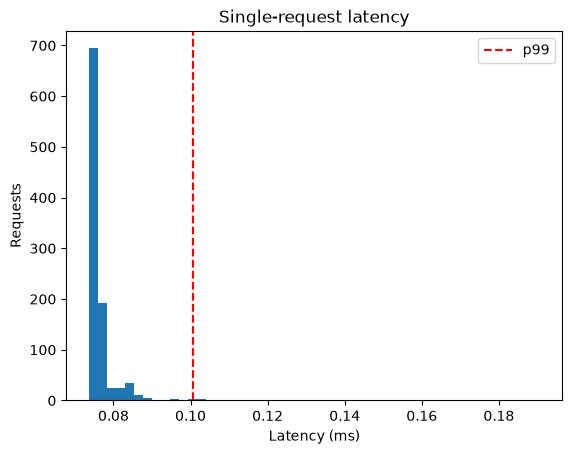

In [2]:
x = torch.randn(1, 256, device=device)

with torch.inference_mode():
    for _ in range(20):          # warm-up
        model(x)
    sync()
    latencies = []
    for _ in range(1000):
        start = time.perf_counter()
        model(x)
        sync()
        latencies.append(time.perf_counter() - start)

lat_ms = np.array(latencies) * 1e3
print(f"mean {lat_ms.mean():.3f} ms | p50 {np.percentile(lat_ms, 50):.3f} | "
      f"p95 {np.percentile(lat_ms, 95):.3f} | p99 {np.percentile(lat_ms, 99):.3f} | max {lat_ms.max():.3f} ms")

plt.hist(lat_ms, bins=50)
plt.axvline(np.percentile(lat_ms, 99), color='red', linestyle='--', label='p99')
plt.xlabel('Latency (ms)')
plt.ylabel('Requests')
plt.title('Single-request latency')
plt.legend()
plt.show()

## 2. Throughput vs. batch size

 batch_size  batch_latency_ms  throughput_samples_per_s
          1              0.08                  13097.13
          8              0.21                  39001.40
         32              0.40                  79952.97
        128              1.58                  80935.05
        512              7.85                  65254.14
       2048             22.62                  90521.54


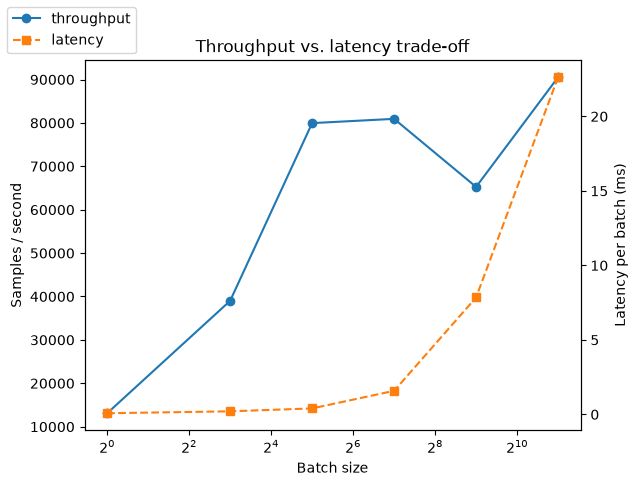

In [3]:
rows = []
with torch.inference_mode():
    for batch_size in [1, 8, 32, 128, 512, 2048]:
        xb = torch.randn(batch_size, 256, device=device)
        model(xb); sync()  # warm-up for this shape
        reps = max(5, 2000 // batch_size)
        start = time.perf_counter()
        for _ in range(reps):
            model(xb)
        sync()
        per_batch = (time.perf_counter() - start) / reps
        rows.append({"batch_size": batch_size,
                     "batch_latency_ms": per_batch * 1e3,
                     "throughput_samples_per_s": batch_size / per_batch})

throughput = pd.DataFrame(rows)
print(throughput.round(2).to_string(index=False))

fig, ax1 = plt.subplots()
ax1.plot(throughput.batch_size, throughput.throughput_samples_per_s, 'o-', label='throughput')
ax1.set_xscale('log', base=2)
ax1.set_xlabel('Batch size')
ax1.set_ylabel('Samples / second')
ax2 = ax1.twinx()
ax2.plot(throughput.batch_size, throughput.batch_latency_ms, 's--', color='tab:orange', label='latency')
ax2.set_ylabel('Latency per batch (ms)')
fig.legend(loc='upper left')
plt.title('Throughput vs. latency trade-off')
plt.show()

## 3. Resource usage: model size and peak memory

In [4]:
from torch.profiler import profile, ProfilerActivity

buffer = io.BytesIO()
torch.save(model.state_dict(), buffer)
print(f"Model size on disk: {buffer.tell() / 1e6:.2f} MB "
      f"(= {sum(p.numel() for p in model.parameters()):,} params x 4 bytes for float32)")

# Activation memory grows with batch size; the profiler can record every tensor allocation
activities = [ProfilerActivity.CPU] + ([ProfilerActivity.CUDA] if device.type == "cuda" else [])
for batch_size in [1, 512]:
    xb = torch.randn(batch_size, 256, device=device)
    with profile(activities=activities, profile_memory=True) as prof, torch.inference_mode():
        model(xb)
    allocated = sum(e.cpu_memory_usage + e.device_memory_usage for e in prof.events() if e.cpu_memory_usage > 0 or e.device_memory_usage > 0)
    print(f"Batch {batch_size:4d}: tensors allocated during forward pass = {allocated / 1e6:.2f} MB")

Model size on disk: 5.29 MB (= 1,323,018 params x 4 bytes for float32)


Batch    1: tensors allocated during forward pass = 0.03 MB
Batch  512: tensors allocated during forward pass = 16.82 MB


## 4. Profiling: where does the time go?

In [5]:
xb = torch.randn(256, 256, device=device)
with profile(activities=activities) as prof, torch.inference_mode():
    for _ in range(20):
        model(xb)
print(prof.key_averages().table(sort_by="self_cpu_time_total", row_limit=6))

----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                  Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
           aten::addmm        95.78%      47.578ms        97.23%      48.296ms     804.925us            60  
       aten::clamp_min         2.01%     999.564us         2.01%     999.564us      24.989us            40  
           aten::copy_         1.22%     608.037us         1.22%     608.037us      10.134us            60  
          aten::linear         0.21%     105.421us        97.90%      48.630ms     810.499us            60  
               aten::t         0.19%      95.898us         0.46%     228.993us       3.817us            60  
      aten::as_strided         0.18%      89.661us         0.18%      89.661us       0.747us           120  
-------------------

In [6]:
# cProfile works for any Python code (e.g. a scikit-learn pipeline)
import cProfile
import pstats
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=5000, n_features=20, random_state=0)
forest = RandomForestClassifier(n_estimators=50, random_state=0)

profiler = cProfile.Profile()
profiler.enable()
forest.fit(X, y)
profiler.disable()
# tottime = time spent inside the function itself, excluding the functions it calls
pstats.Stats(profiler).strip_dirs().sort_stats("tottime").print_stats(8);

         141391 function calls (140045 primitive calls) in 0.570 seconds

   Ordered by: internal time
   List reduced from 361 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       50    0.463    0.009    0.512    0.010 _classes.py:226(_fit)
      101    0.008    0.000    0.008    0.000 _ufunc_config.py:496(inner)
      151    0.007    0.000    0.016    0.000 validation.py:1455(check_random_state)
      302    0.005    0.000    0.017    0.000 inspect.py:2397(_signature_from_function)
       50    0.005    0.000    0.532    0.011 _forest.py:132(_parallel_build_trees)
     3877    0.004    0.000    0.007    0.000 inspect.py:2743(__init__)
       50    0.004    0.000    0.014    0.000 _forest.py:95(_generate_sample_indices)
      102    0.003    0.000    0.007    0.000 _arraysetops_impl.py:350(_unique1d)


